In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder ,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans,AgglomerativeClustering
from kneed import KneeLocator

In [4]:
df=pd.read_csv(r"C:\Users\soham\OneDrive\Documents\Smart_Cart_Clustering\Data\smartcart_customers.csv")
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,42,118,247,2,9,3,4,5,0,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,0,0,8,7,8,2,5,7,0,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,32,12,24,1,2,3,13,6,0,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,80,30,61,2,6,5,10,3,0,0


In [6]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [7]:
imputer =SimpleImputer(strategy="mean")

In [8]:
df[["Income"]]=imputer.fit_transform(df[["Income"]])

In [9]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

In [10]:
#Feautre engineering 
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='str')

In [11]:
# we will change the year birth to age
df["Age"]=2026-df["Year_Birth"]
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,118,247,2,9,3,4,5,0,0,59
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,0,8,7,8,2,5,7,0,0,80
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,12,24,1,2,3,13,6,0,0,45
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,30,61,2,6,5,10,3,0,0,70


In [12]:
# now we will add a customer tenure time from date of joining
# to do so first we will change dt customer format from dd mm yy to mm dd yy 
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"],dayfirst=True)

In [13]:
# now we will make a reference date which is the maximum date of joining of a customer
refrence_date=df["Dt_Customer"].max()


In [14]:
df["Customer_Tenure_Time"]=(refrence_date-df["Dt_Customer"]).dt.days

In [15]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Time
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,...,247,2,9,3,4,5,0,0,59,381
2236,4001,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,...,8,7,8,2,5,7,0,0,80,19
2237,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,...,24,1,2,3,13,6,0,0,45,155
2238,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,...,61,2,6,5,10,3,0,0,70,156


In [16]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Time'],
      dtype='str')

In [17]:
df["Total_Spending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]

In [18]:
df["Total_Children"]=df["Kidhome"]+df["Teenhome"]

In [19]:
df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [20]:
df["Education"]=df["Education"].replace({
    "Basic":"UnderGraduate","2n Cycle":"UnderGraduate",
    "Graduation":"Graduate",
    "PhD":"PostGraduate",
    "Master":"PostGraduate"
})

In [21]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [22]:
df["Living_With"]=df["Marital_Status"].replace({
    "Married":"Partner","Together":"Partner",
    "Single":"Alone","Divorced":"Alone","Widow":"Alone","Absurd":"Alone","YOLO":"Alone"
})

In [23]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Time,Total_Spending,Total_Children,Living_With
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,PostGraduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduate,Married,61223.0,0,1,2013-06-13,46,709,...,3,4,5,0,0,59,381,1341,1,Partner
2236,4001,1946,PostGraduate,Together,64014.0,2,1,2014-06-10,56,406,...,2,5,7,0,0,80,19,444,3,Partner
2237,7270,1981,Graduate,Divorced,56981.0,0,0,2014-01-25,91,908,...,3,13,6,0,0,45,155,1241,0,Alone
2238,8235,1956,PostGraduate,Together,69245.0,0,1,2014-01-24,8,428,...,5,10,3,0,0,70,156,843,1,Partner


In [24]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Time', 'Total_Spending',
       'Total_Children', 'Living_With'],
      dtype='str')

In [41]:
df_cleaned=df.drop(columns=["ID","Marital_Status","Year_Birth","Kidhome","Teenhome","Dt_Customer","MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"])

In [42]:
df_cleaned

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Time,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,PostGraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,Graduate,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,Partner
2236,PostGraduate,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,Partner
2237,Graduate,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,Alone
2238,PostGraduate,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,Partner


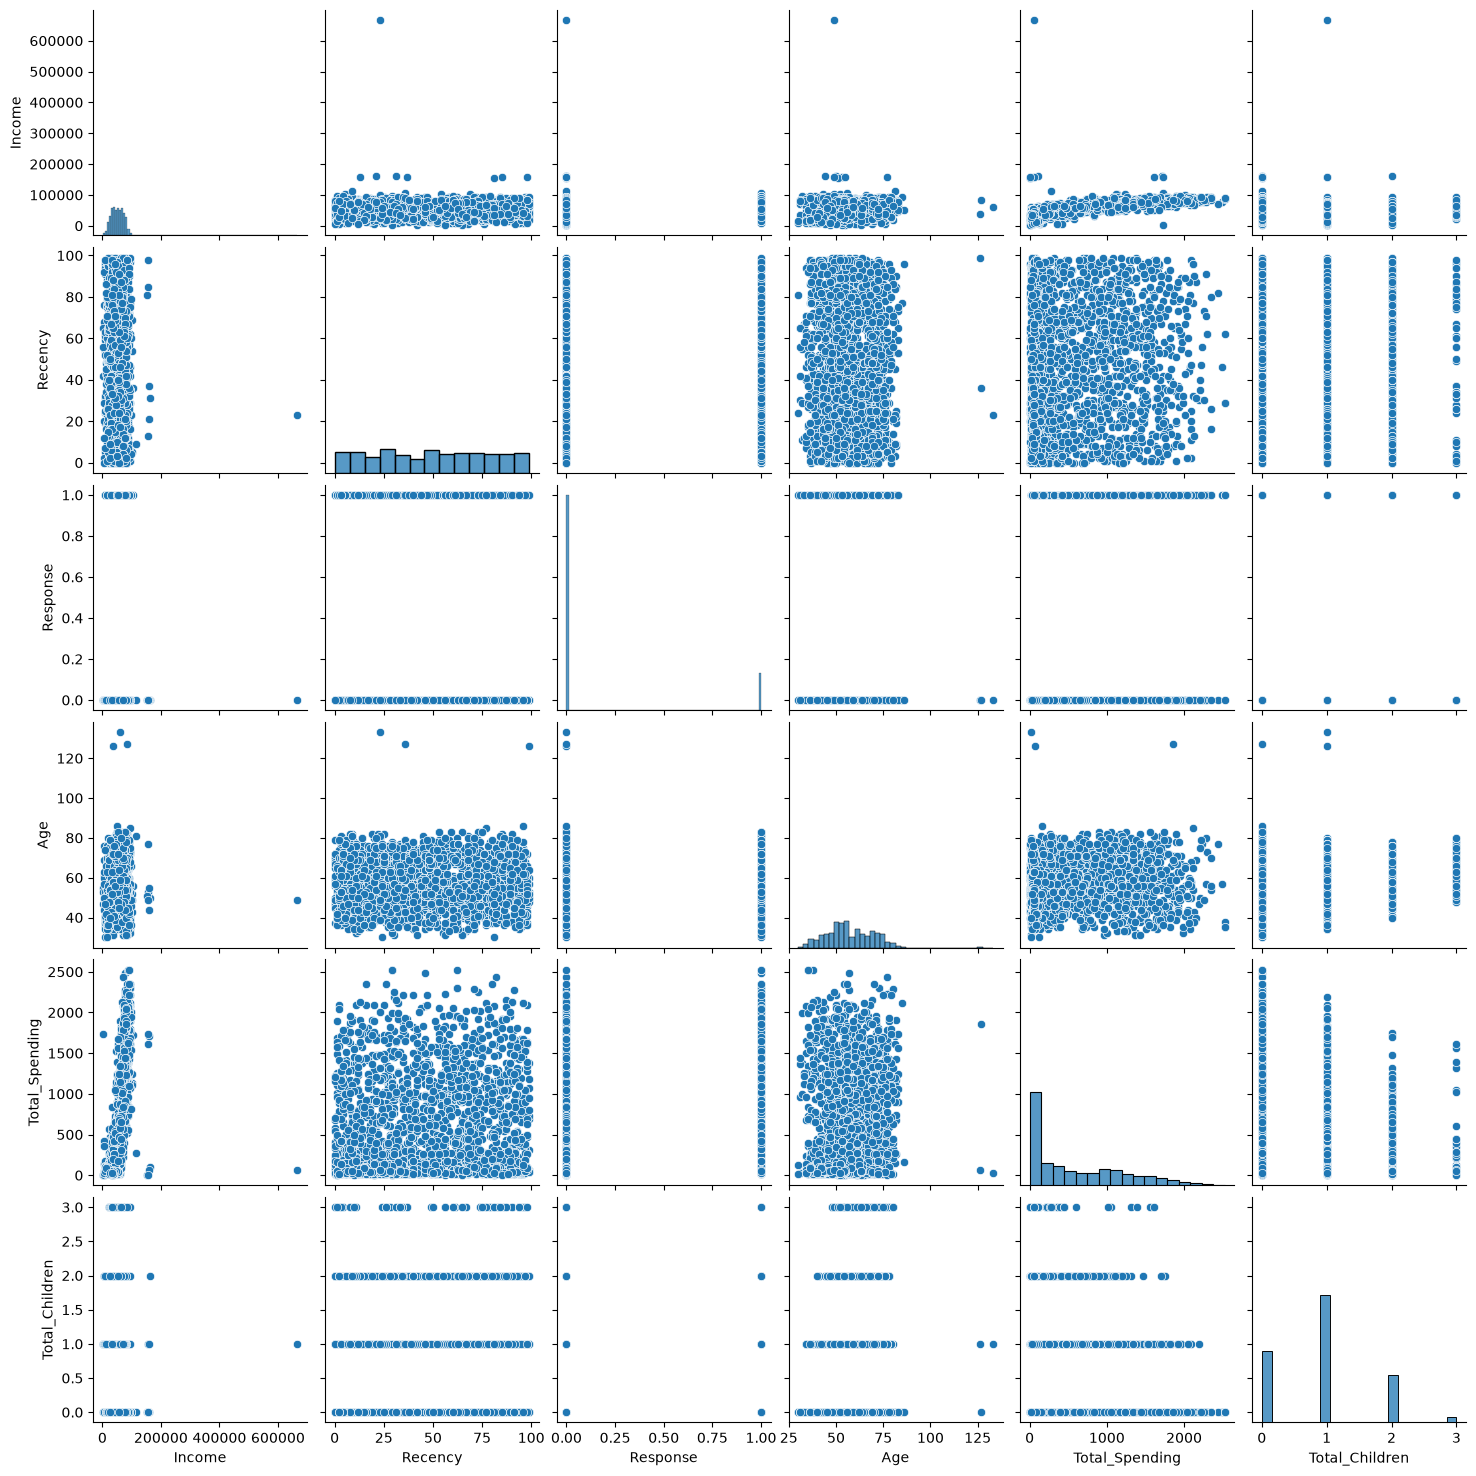

In [43]:
num_cols=["Income","Recency","Response","Age","Total_Spending","Total_Children"]
sns.pairplot(df_cleaned[num_cols])

In [44]:
print("size of df before outlier removal :",len(df_cleaned))
df_cleaned=df_cleaned[(df_cleaned["Age"]<120)]
df_cleaned=df_cleaned[(df_cleaned["Income"]<600_000)]
print("size of df after outlier removal :",len(df_cleaned))

size of df before outlier removal : 2240
size of df after outlier removal : 2236


CORRELATION HEATMAP

In [45]:
corr=df_cleaned.corr(numeric_only=True)

<Axes: >

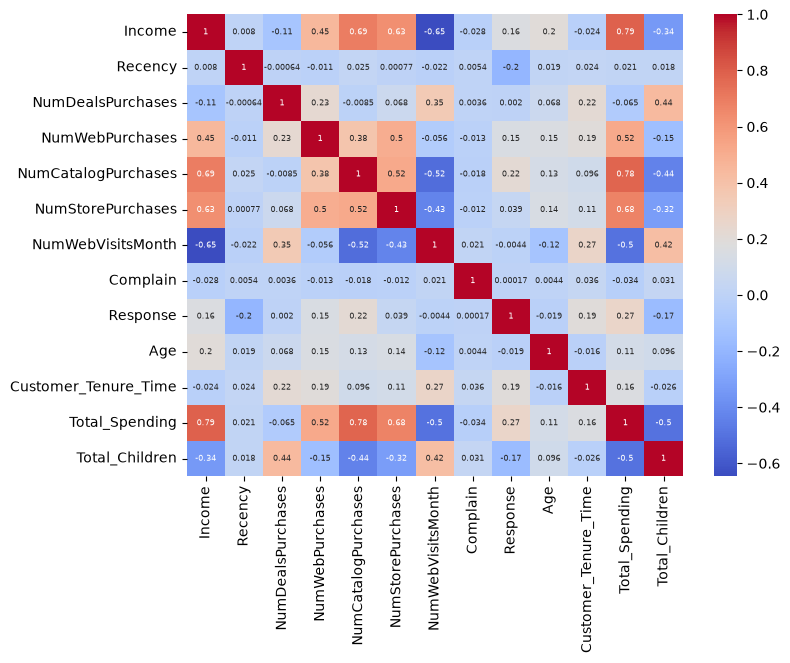

In [46]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)

Feature encoding nd scaling


In [47]:
df_cleaned.info()

<class 'pandas.DataFrame'>
Index: 2236 entries, 0 to 2239
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Education             2236 non-null   str    
 1   Income                2236 non-null   float64
 2   Recency               2236 non-null   int64  
 3   NumDealsPurchases     2236 non-null   int64  
 4   NumWebPurchases       2236 non-null   int64  
 5   NumCatalogPurchases   2236 non-null   int64  
 6   NumStorePurchases     2236 non-null   int64  
 7   NumWebVisitsMonth     2236 non-null   int64  
 8   Complain              2236 non-null   int64  
 9   Response              2236 non-null   int64  
 10  Age                   2236 non-null   int64  
 11  Customer_Tenure_Time  2236 non-null   int64  
 12  Total_Spending        2236 non-null   int64  
 13  Total_Children        2236 non-null   int64  
 14  Living_With           2236 non-null   str    
dtypes: float64(1), int64(12), str(2)
memo

In [48]:
df_cleaned.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'Customer_Tenure_Time', 'Total_Spending', 'Total_Children',
       'Living_With'],
      dtype='str')

In [49]:
categorical_cols=["Education","Living_With"]
ohe=OneHotEncoder(sparse_output=False)
encoded_cols=ohe.fit_transform(df_cleaned[categorical_cols])
encoded_df=pd.DataFrame(encoded_cols,columns=ohe.get_feature_names_out(categorical_cols),index=df_cleaned.index)

In [50]:
encoded_df

,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...
2235,1.0,0.0,0.0,0.0,1.0
2236,0.0,1.0,0.0,0.0,1.0
2237,1.0,0.0,0.0,1.0,0.0
2238,0.0,1.0,0.0,0.0,1.0


In [51]:
df_encoded=pd.concat([df_cleaned,encoded_df],axis=1)

In [52]:
df_encoded

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Time,Total_Spending,Total_Children,Living_With,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_With_Alone,Living_With_Partner
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone,1.0,0.0,0.0,1.0,0.0
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone,1.0,0.0,0.0,1.0,0.0
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner,1.0,0.0,0.0,0.0,1.0
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner,1.0,0.0,0.0,0.0,1.0
4,PostGraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,Graduate,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,Partner,1.0,0.0,0.0,0.0,1.0
2236,PostGraduate,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,Partner,0.0,1.0,0.0,0.0,1.0
2237,Graduate,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,Alone,1.0,0.0,0.0,1.0,0.0
2238,PostGraduate,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,Partner,0.0,1.0,0.0,0.0,1.0


In [53]:
df_encoded=df_encoded.drop(columns=["Living_With","Education"])

In [54]:
df_encoded

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Time,Total_Spending,Total_Children,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,1.0,0.0,0.0,0.0,1.0
2236,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,0.0,1.0,0.0,0.0,1.0
2237,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,1.0,0.0,0.0,1.0,0.0
2238,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,0.0,1.0,0.0,0.0,1.0


SCALING


In [55]:
scaler=StandardScaler()
df_scaled=scaler.fit_transform(df_encoded)

In [56]:
df_scaled

array([[ 0.2885133 ,  0.30685572,  0.34873831, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [-0.26243786, -0.38397129, -0.16869955, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.91799157, -0.7984675 , -0.68613742, ..., -0.35877969,
        -0.74204052,  0.74204052],
       ...,
       [ 0.23446459,  1.44672029, -0.68613742, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.80737157, -1.42021181, -0.16869955, ..., -0.35877969,
        -0.74204052,  0.74204052],
       [ 0.04237444, -0.31488859,  0.34873831, ..., -0.35877969,
        -0.74204052,  0.74204052]], shape=(2236, 18))

In [57]:
pca=PCA(n_components=2)
pca_df=pca.fit_transform(df_scaled)

In [58]:
pca_df.shape

(2236, 2)

<Axes: >

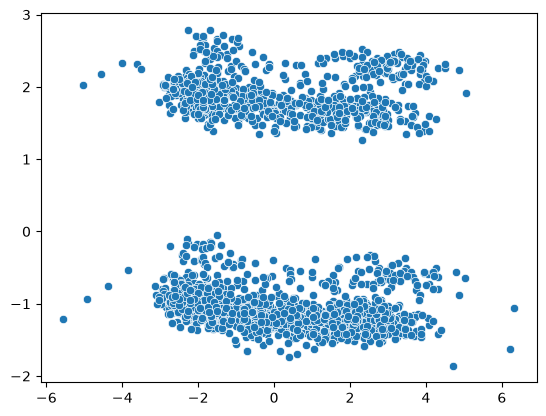

In [59]:
sns.scatterplot(x=pca_df[:,0],y=pca_df[:,1])

In [60]:
pca.explained_variance_ratio_

array([0.23162286, 0.11385437])

In [61]:
pca=PCA(n_components=3)
pca_df=pca.fit_transform(df_scaled)

<Axes: >

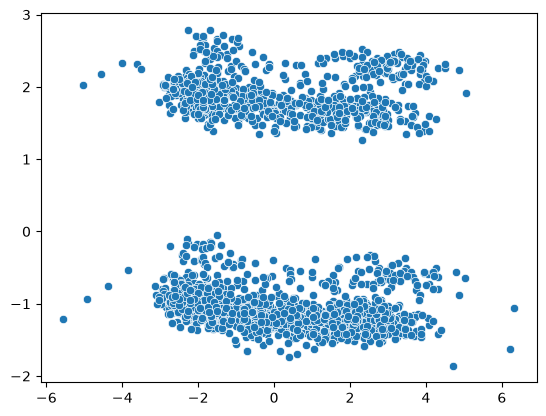

In [62]:
sns.scatterplot(x=pca_df[:,0],y=pca_df[:,1])

In [63]:
pca.explained_variance_ratio_

array([0.23162286, 0.11385437, 0.1040582 ])

Text(0.5, 0, 'PCA 3')

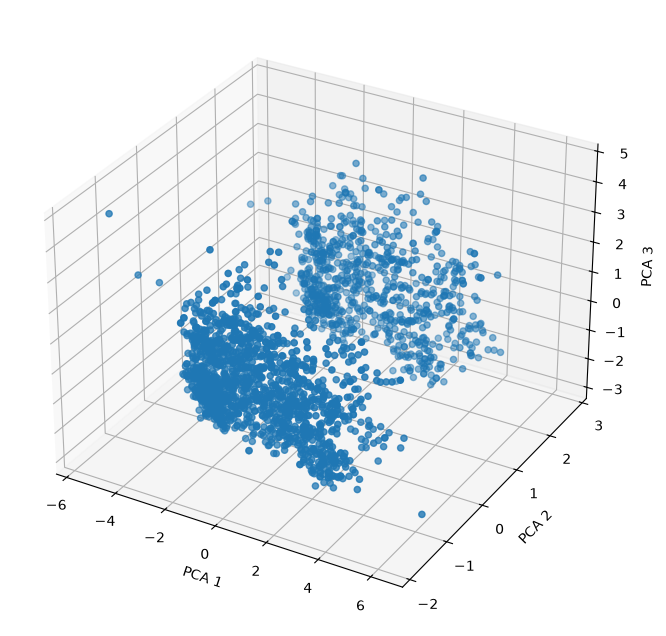

In [64]:
fig=plt.figure(figsize=(10,8))
ax=plt.subplot(111,projection="3d")
ax.scatter(pca_df[:,0],pca_df[:,1],pca_df[:,2])
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")


CHOOSE K

In [65]:
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k)
    kmeans.fit_predict(pca_df)
    wcss.append(kmeans.inertia_)

In [66]:
knee=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
print("optimal knee is :",knee.elbow)

optimal knee is : 4


In [67]:
kmeans_model=KMeans(n_clusters=4)
kmeans_labels=kmeans_model.fit_predict(pca_df)

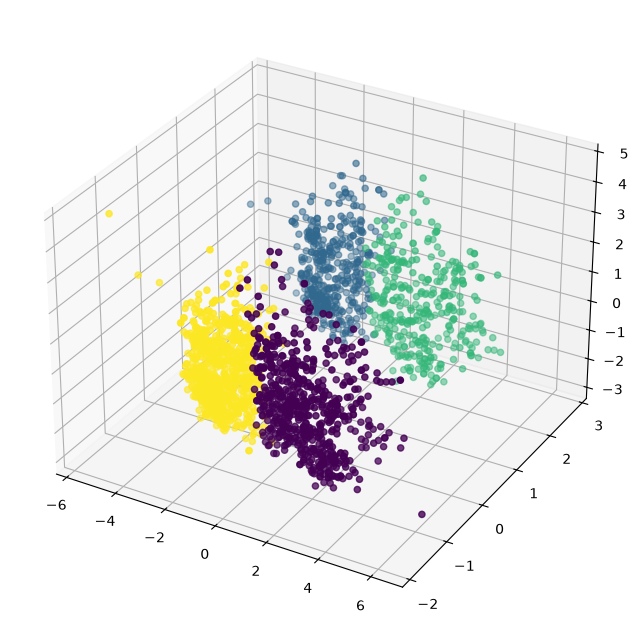

In [68]:
fig=plt.figure(figsize=(10,8))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(pca_df[:,0],pca_df[:,1],pca_df[:,2],c=kmeans_labels)

AGGLOMERATIVE MODEL

In [69]:
agl_model=AgglomerativeClustering(n_clusters=4)
agl_model_labels=agl_model.fit_predict(pca_df)

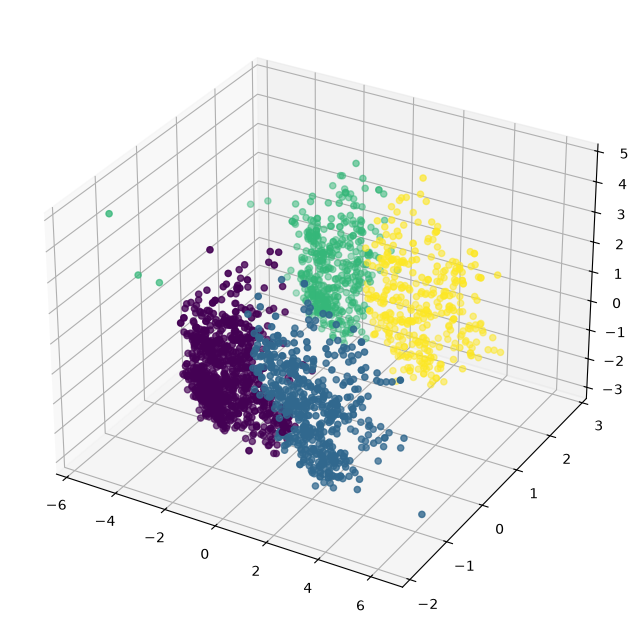

In [70]:
fig=plt.figure(figsize=(10,8))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(pca_df[:,0],pca_df[:,1],pca_df[:,2],c=agl_model_labels)

In [71]:
df_cleaned["Labels"]=agl_model_labels
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Time,Total_Spending,Total_Children,Living_With,Labels
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone,3
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone,2
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner,1
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner,0
4,PostGraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner,0


<Axes: xlabel='Income', ylabel='Total_Spending'>

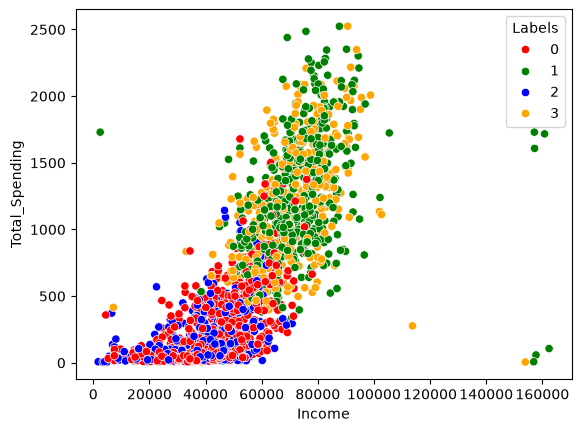

In [75]:
#income vs total spending
pal=["red","green","blue","orange"]
sns.scatterplot(x=df_cleaned["Income"],y=df_cleaned["Total_Spending"],hue=df_cleaned["Labels"],palette=pal)